# 6. Results and comparison

Notebook 3 built the cost model on synthetic scores. Notebook 4 produced real ones
for MetroPT. This notebook puts the real scores through exactly the same functions
from `util/evaluation.py` and answers three questions:

1. Which threshold costs least, and what does it catch and miss?
2. How much warning does it give before each failure?
3. Does the choice survive a different cost ratio? On synthetic data it did not move
   at all between 1 : 7 and 1 : 100.

Then the same for Kelmarsh, and the comparison between the two.

In [1]:
import sys
sys.path.insert(0, '..')

from pathlib import Path

import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

from util.evaluation import alarms, evaluate

FIGURES = Path('../figures')
RESULTS = Path('../results')

COST_FALSE_ALARM = 1
COST_MISSED = 20

## MetroPT: the scores

One score per 10-minute row, from the KDE in notebook 4. Higher means less like
February and March.

In [2]:
scores = pd.read_csv(RESULTS / 'metropt_scores.csv', index_col='timestamp', parse_dates=True)['score']

print(f'{len(scores):,} rows from {scores.index.min()} to {scores.index.max()}')
scores.describe(percentiles=[0.5, 0.9, 0.99]).round(1)

25,521 rows from 2020-02-01 00:00:00 to 2020-09-01 03:50:00


count    25521.0
mean        11.0
std         30.9
min          3.7
50%          5.2
90%          7.1
99%        193.4
max        350.0
Name: score, dtype: float64

### The series has holes. Does that matter?

Notebook 4 dropped every row with a sensor gap, so the rows are not evenly spaced.
`alarms()` and `evaluate()` only compare timestamps (is this alarm within 6 hours of
the last one, does it fall inside a failure's window), never row numbers, so the
holes do not break anything. What they *can* do is hide a failure: if the sensors
were off during it, there is nothing to score. So we count the gaps, and below we
check how many rows each failure actually has.

In [3]:
step = scores.index.to_series().diff()
print(f'rows 10 minutes apart: {(step == pd.Timedelta("10min")).mean():.1%}')
print(f'gaps longer than 6 hours: {(step > pd.Timedelta("6h")).sum()}, longest {step.max()}')

rows 10 minutes apart: 99.2%
gaps longer than 6 hours: 29, longest 2 days 00:00:00


## MetroPT: the failures

Dates from the dataset documentation. **The end has to be written as 23:50**, the
last 10-minute row of the day. Notebooks 1 and 4 write `('2020-04-18', '2020-04-18')`,
which is fine for slicing (pandas then takes the whole day), but `evaluate()` turns
it into a single `Timestamp` and the end becomes midnight, so F1 would last zero
minutes.

In [4]:
FAILURES = [
    ('2020-04-18', '2020-04-18 23:50'),   # F1
    ('2020-05-29', '2020-05-30 23:50'),   # F2
    ('2020-06-05', '2020-06-07 23:50'),   # F3
    ('2020-07-15', '2020-07-15 23:50'),   # F4
]
NAMES = ['F1', 'F2', 'F3', 'F4']

rows = []
for name, (start, end) in zip(NAMES, FAILURES):
    inside = scores[start:end]
    before = scores[pd.Timestamp(start) - pd.Timedelta('2D'):pd.Timestamp(start) - pd.Timedelta('10min')]
    possible = (pd.Timestamp(end) - pd.Timestamp(start)) / pd.Timedelta('10min') + 1
    rows.append({'failure': name, 'rows': len(inside), 'possible rows': int(possible),
                 'median score inside': inside.median(), 'max inside': inside.max(),
                 'max in 2 days before': before.max()})

pd.DataFrame(rows).set_index('failure').round(1)

,rows,possible rows,median score inside,max inside,max in 2 days before
failure,,,,,
F1,144,144,144.5,162.5,44.3
F2,270,288,5.5,177.4,9.8
F3,348,432,191.0,234.7,115.1
F4,144,144,8.3,49.2,61.4


F2 and F3 lose some rows to gaps but keep most of them, so none of the four is
hidden. F2's median is at normal level: the leak shows for only part of its two-day
label, as notebook 4 found. F4 never gets above 50 inside its own window; its highest
score is in the two days before.

## Evaluate from April only

The KDE was fitted on February and March, so it has seen those rows. Scoring them
counts in its favour, so we leave them out and evaluate from 1 April. This removes
exactly one false alarm, so it changes nothing, but it is the honest way to report it.

In [5]:
test = scores['2020-04-01':]
test_days = (test.index.max() - test.index.min()) / pd.Timedelta('1D')
print(f'evaluation period: {test.index.min().date()} to {test.index.max().date()}, {test_days:.0f} days')

evaluation period: 2020-04-01 to 2020-09-01, 153 days


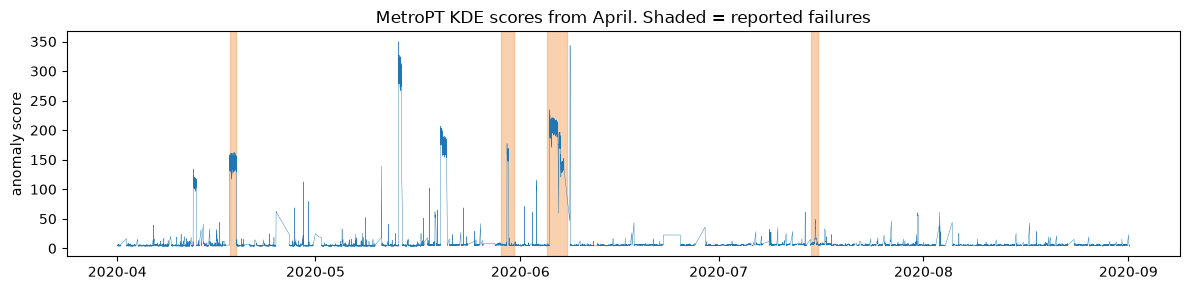

In [6]:
def mark_failures(ax, failures):
    for start, end in failures:
        ax.axvspan(pd.Timestamp(start), pd.Timestamp(end), color='sandybrown', alpha=0.5)


fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(test.index, test, lw=0.3, color='tab:blue')
mark_failures(ax, FAILURES)
ax.set_ylabel('anomaly score')
ax.set_title('MetroPT KDE scores from April. Shaded = reported failures')
plt.tight_layout()

Every failure is visible, but so are several excursions just as tall where nothing
was reported. That is the problem the cost model has to settle.

## MetroPT: cost against threshold

Same sweep as notebook 3, on a grid of whole numbers from 5 to 350 (the range of the
scores). False alarm = 1, missed failure = 20.

In [7]:
thresholds = np.arange(5, 351, 1.0)
sweep = pd.DataFrame([evaluate(test, FAILURES, t) for t in thresholds], index=thresholds)
sweep['cost'] = sweep['false_alarms'] * COST_FALSE_ALARM + sweep['missed'] * COST_MISSED

# Ties go to the lowest threshold: it alarms earlier.
best = sweep.index[sweep['cost'] == sweep['cost'].min()].min()
sweep.loc[best, ['detected', 'missed', 'false_alarms', 'cost']]

detected         4
missed           0
false_alarms    22
cost            22
Name: 61.0, dtype: int64

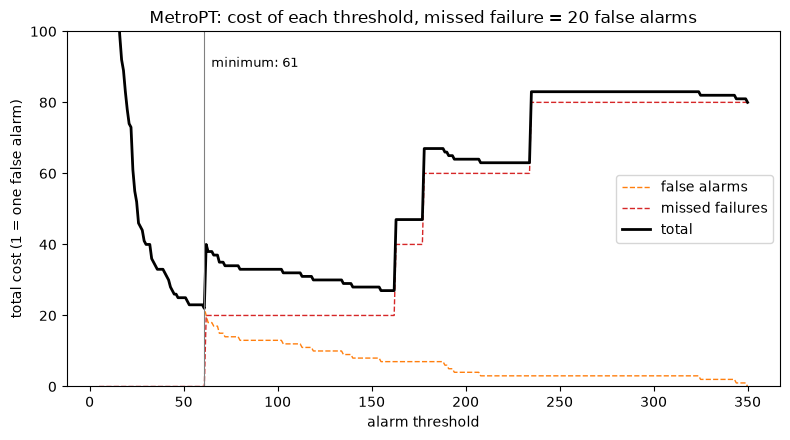

In [8]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(sweep.index, sweep['false_alarms'] * COST_FALSE_ALARM,
        color='tab:orange', lw=1, ls='--', label='false alarms')
ax.plot(sweep.index, sweep['missed'] * COST_MISSED,
        color='tab:red', lw=1, ls='--', label='missed failures')
ax.plot(sweep.index, sweep['cost'], color='black', lw=2, label='total')
ax.axvline(best, color='grey', lw=0.8)
ax.annotate(f'minimum: {best:.0f}', (best, 90), xytext=(5, 0), textcoords='offset points', fontsize=9)

ax.set_ylim(0, 100)
ax.set_xlabel('alarm threshold')
ax.set_ylabel('total cost (1 = one false alarm)')
ax.set_title(f'MetroPT: cost of each threshold, missed failure = {COST_MISSED} false alarms')
ax.legend()
plt.tight_layout()
fig.savefig(FIGURES / 'metropt_cost_vs_threshold.png', dpi=200)

The curve does not have one clear bottom. It has two shelves: one around 60 where
all four failures are caught, and one from about 135 to 160 where F4 is given up
and the false alarms drop to single figures. Zoomed in:

In [9]:
sweep.loc[[40, 50, 55, 60, 61, 62, 70, 100, 130, 150, 155, 160, 165],
          ['detected', 'false_alarms', 'cost']].T

,40.0,50.0,55.0,60.0,61.0,62.0,70.0,100.0,130.0,150.0,155.0,160.0,165.0
detected,4,4,4,4,4,3,3,3,3,3,3,3,2
false_alarms,32,25,23,23,22,20,15,13,10,8,7,7,7
cost,32,25,23,23,22,40,35,33,30,28,27,27,47


Two things stand out.

**The minimum is a knife-edge.** At 61 all four failures are caught; at 62, F4 is
lost and cost jumps by 20. This is the lopsided shape notebook 3 warned about, and
the reason the rule in `DECISIONS.md` is to sit at or a little below the minimum.

**The two shelves are only a few units apart.** Catching F4 costs about 15 extra
false alarms, against the 20 a miss is worth. As predicted from notebook 4: a shallow
minimum.

## MetroPT: what the chosen threshold does

In [10]:
result = evaluate(test, FAILURES, best)

print(f'threshold {best:.0f}')
print(f'detected {result["detected"]} of {len(FAILURES)}, missed {result["missed"]}')
print(f'false alarms {result["false_alarms"]} in {test_days:.0f} days, '
      f'one every {test_days / result["false_alarms"]:.1f} days')

lead_hours = (result['lead_times'].dt.total_seconds() / 3600).round(1)
lead_hours.index = NAMES
lead_hours.rename('hours of warning (negative = after it started)')

threshold 61
detected 4 of 4, missed 0
false alarms 22 in 153 days, one every 7.0 days


F1    -0.3
F2   -23.3
F3    37.8
F4    21.7
Name: hours of warning (negative = after it started), dtype: float64

Only F3 gets real warning, a day and a half. F1 is caught 20 minutes after it
starts, F2 almost a day into its two-day window.

### Is F4 really detected?

F4 is caught by one alarm about 22 hours before the reported date. Nothing inside
F4's own window crosses the threshold. With a false alarm every week or so, how
likely is it that one lands in F4's window by pure chance? The window is the 2 days
of `lead` plus the day of the failure.

In [11]:
false_per_day = result['false_alarms'] / test_days
window_days = 2 + 1
print(f'false alarms expected in a random 3-day window: {false_per_day * window_days:.2f}')

false alarms expected in a random 3-day window: 0.43


Roughly two chances in five. So the "detection" of F4 at threshold 61 is
indistinguishable from luck, and the notebook 1 finding stands: there is no visible
F4 signature. Honestly reported, the detector catches **three of four** failures,
and the cheapest threshold catches the fourth by chance.

### Where do the false alarms happen?

April      7
May       11
June       3
August     1
Name: count, dtype: int64

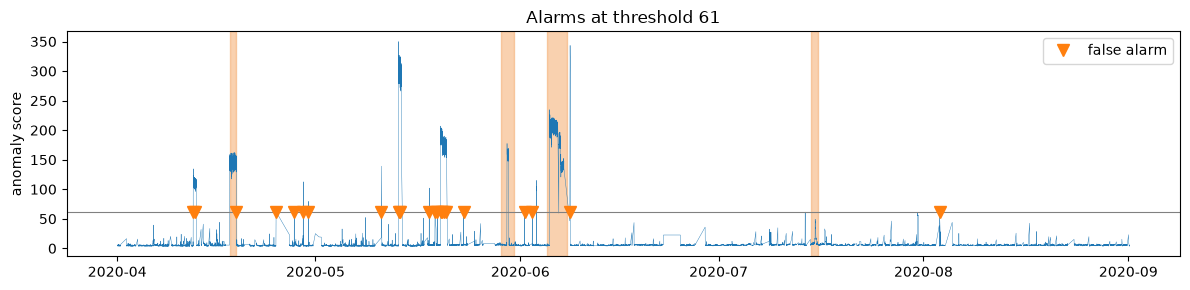

In [12]:
false_alarm_times = [t for t in result['alarms']
                     if not any(pd.Timestamp(s) - pd.Timedelta('2D') <= t <= pd.Timestamp(e)
                                for s, e in FAILURES)]

fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(test.index, test, lw=0.3, color='tab:blue')
mark_failures(ax, FAILURES)
ax.axhline(best, color='grey', lw=0.8)
ax.plot(false_alarm_times, [best] * len(false_alarm_times), 'v', color='tab:orange',
        markersize=8, label='false alarm')
ax.set_ylabel('anomaly score')
ax.set_title(f'Alarms at threshold {best:.0f}')
ax.legend()
plt.tight_layout()
fig.savefig(FIGURES / 'metropt_false_alarms.png', dpi=200)

pd.Series(pd.DatetimeIndex(false_alarm_times).month_name()).value_counts(sort=False)

Almost all of them fall between April and June, and only one after F4. Half come
from one stretch, 13–23 May, which includes the highest score in the whole series
(350). That is the unreported mid-May excursion from the open questions in
`DECISIONS.md`. Most of the rest come in the days just after F1, F2 and F3 end,
when the score has not yet settled. Whether those are false or a leak that was not
fully fixed, we cannot tell from the labels. So 22 is an upper bound on what a
technician would really have found nothing on.

## MetroPT: lead time against threshold

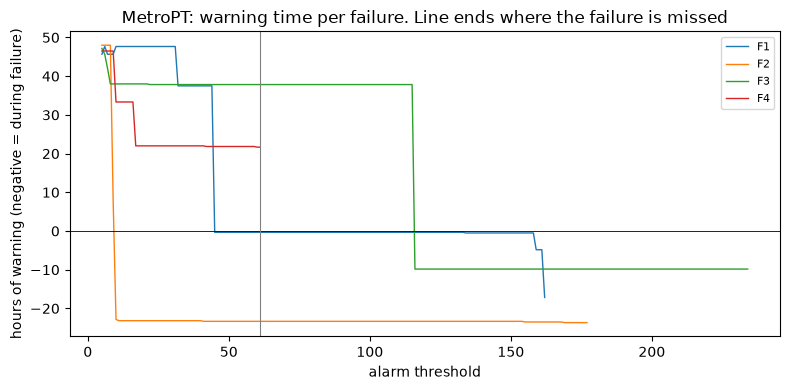

In [13]:
hours = pd.DataFrame([lt.dt.total_seconds() / 3600 for lt in sweep['lead_times']], index=sweep.index)
hours.columns = NAMES

fig, ax = plt.subplots(figsize=(8, 4))
for name in NAMES:
    ax.plot(hours.index, hours[name], lw=1, label=name)
ax.axhline(0, color='black', lw=0.6)
ax.axvline(best, color='grey', lw=0.8)
ax.set_xlabel('alarm threshold')
ax.set_ylabel('hours of warning (negative = during failure)')
ax.set_title('MetroPT: warning time per failure. Line ends where the failure is missed')
ax.legend(fontsize=8)
plt.tight_layout()

**F3's warning comes from one alarm.** On 3 June, a day and a half before F3, the
score reaches 115. Any threshold up to 115 catches it; at 116 that warning is gone
and F3 is only seen 10 hours after it starts. F1 gets a similar warning only below
about 44, which costs 30+ false alarms. F2 is always caught almost a day into its
window. So above 115, the detector gives **no early warning on any failure**: it
only confirms leaks that are already under way.

## MetroPT: does the threshold move with the cost ratio?

On synthetic data the chosen threshold stayed put from 1 : 7 to 1 : 100. Here:

,threshold,detected,false alarms
missed costs,,,
5,155.0,3,7
20,61.0,4,22
100,61.0,4,22


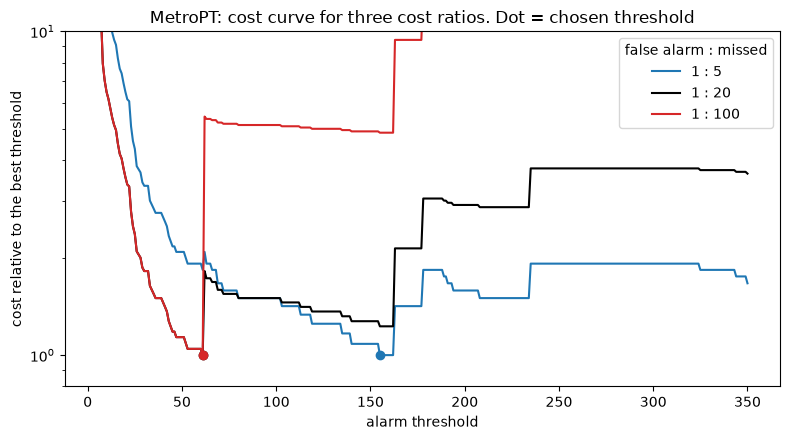

In [14]:
fig, ax = plt.subplots(figsize=(8, 4.5))

rows = []
for ratio, colour in [(5, 'tab:blue'), (20, 'black'), (100, 'tab:red')]:
    cost = sweep['false_alarms'] + sweep['missed'] * ratio
    chosen = cost.index[cost == cost.min()].min()
    ax.plot(cost.index, cost / cost.min(), color=colour, lw=1.5, label=f'1 : {ratio}')
    ax.plot(chosen, 1, 'o', color=colour)
    r = sweep.loc[chosen]
    rows.append({'missed costs': ratio, 'threshold': chosen,
                 'detected': r['detected'], 'false alarms': r['false_alarms']})

ax.set_ylim(0.8, 10)
ax.set_yscale('log')
ax.set_xlabel('alarm threshold')
ax.set_ylabel('cost relative to the best threshold')
ax.set_title('MetroPT: cost curve for three cost ratios. Dot = chosen threshold')
ax.legend(title='false alarm : missed')
plt.tight_layout()
fig.savefig(FIGURES / 'metropt_cost_ratio_sensitivity.png', dpi=200)

pd.DataFrame(rows).set_index('missed costs')

1     350.0
3     155.0
15     61.0
dtype: float64

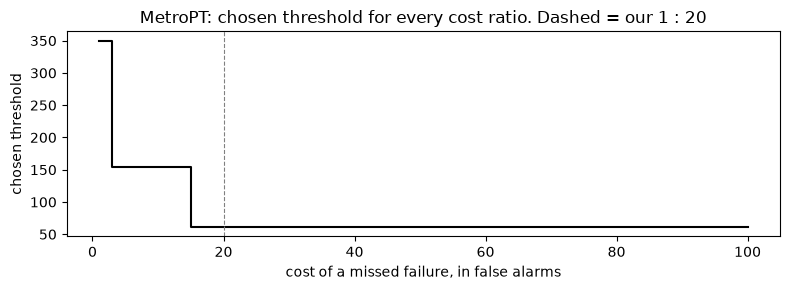

In [15]:
ratios = np.arange(1, 101)
chosen = []
for ratio in ratios:
    cost = sweep['false_alarms'] + sweep['missed'] * ratio
    chosen.append(cost.index[cost == cost.min()].min())
chosen = pd.Series(chosen, index=ratios)

fig, ax = plt.subplots(figsize=(8, 3))
ax.step(ratios, chosen, where='post', color='black')
ax.axvline(COST_MISSED, color='grey', lw=0.8, ls='--')
ax.set_xlabel('cost of a missed failure, in false alarms')
ax.set_ylabel('chosen threshold')
ax.set_title('MetroPT: chosen threshold for every cost ratio. Dashed = our 1 : 20')
plt.tight_layout()
fig.savefig(FIGURES / 'metropt_threshold_vs_ratio.png', dpi=200)

# The ratios at which the choice changes
chosen[chosen.diff() != 0]

**The synthetic result does not hold.** The choice is still a step function with
only a few steps, but the step that matters now sits at about 1 : 15, just below our
1 : 20. Under 15 the cheapest threshold is about 155 (three failures, 7 false
alarms); above it, about 61 (four failures, 22 false alarms). A small change in a
cost we guessed flips the decision.

The step is about F4 only, and F4 is the failure we just saw is caught by luck.
Setting F4 aside, the cost model picks the shelf at 155, but there the detector
gives no warning on anything. Our rule from notebook 3 is to err low, because a
lower threshold warns earlier. Erring low to **110**, a little under F3's 115
precursor, keeps the day and a half of warning on F3 for 5 more false alarms.

In [16]:
CHOSEN = 110

rows = []
for t in [best, CHOSEN, 155]:
    r = evaluate(test, FAILURES, t)
    row = {'threshold': t, 'detected': r['detected'], 'false alarms': r['false_alarms'],
           'cost at 1 : 20': r['false_alarms'] + r['missed'] * COST_MISSED}
    for name, lt in zip(NAMES, r['lead_times']):
        row[f'{name} warning (h)'] = round(lt.total_seconds() / 3600, 1)
    rows.append(row)

pd.DataFrame(rows).set_index('threshold')

,detected,false alarms,cost at 1 : 20,F1 warning (h),F2 warning (h),F3 warning (h),F4 warning (h)
threshold,,,,,,,
61.0,4,22,22,-0.3,-23.3,37.8,21.7
110.0,3,12,32,-0.3,-23.3,37.8,NaN
155.0,3,7,27,-0.5,-23.5,-9.8,NaN


## MetroPT: summary

| threshold | 61 (cost minimum at 1 : 20) | 110 (our choice) | 155 (cheapest without F4) |
|---|---|---|---|
| detected | 4 of 4, F4 probably by chance | 3 of 4 | 3 of 4 |
| false alarms, Apr–Sep (153 days) | 22 | 12 | 7 |
| cost at 1 : 20 | 22 | 32 | 27 |
| warning before F3 | 1.5 days | 1.5 days | none (10 h late) |
| F1, F2 | caught after they started | same | same |

The method works on MetroPT for the failures that leave a mark in the sensors
(F1–F3), and gives real early warning for one of them. The price is a false alarm
every one to three weeks. The cost model on its own does not see that the cheapest
point gives no warning: lead time has to be read next to the cost curve.

### Would averaging over an hour have given more warning?

The obvious objection to the summary above: the detector scores each 10-minute
reading on its own, so perhaps it is late on F1 and F2 only because single readings
are noisy. Notebook 7 tested that. It feeds the same KDE the mean of the last hour
instead of single readings, and compares the two at the same false alarm budget
(about twenty from April), so neither can win by alarming more often.

It makes no difference. Warning times move by less than half an hour on every
failure both detectors find (F1 0.3 h vs 0.5 h late, F2 23.3 h vs 23.7 h late, F3
37.8 h vs 37.3 h early). The windowed version also fires inside F4, but by the
chance check above that is what a random alarm does about four times in ten.

So the lateness is not a filtering problem: the sensors carry no sign of F1 and F2
before they begin. We keep the per-reading scores. The windowed scores are kept in
`results/metropt_scores_1h.csv` if anyone wants to rerun this notebook on them.

## Kelmarsh: the scores and the outages

Notebook 5 scored all six turbines with the same KDE recipe, one model per turbine,
trained on 22 April to 3 June. The failures are the forced outages from the status
log, with overlapping lines merged into one event, built exactly as in notebooks 2
and 5.

Three choices, made so the MetroPT steps carry over unchanged:

- **One threshold for the whole farm.** All six models use the same recipe and the
  same bandwidth, so their scores are on the same scale (median 4.3 to 4.5 on every
  turbine). One number is one rule to explain. Detections, misses and false alarms
  are added up over the six turbines.
- **Leave out the training period**, as we left out February and March on MetroPT.
- **Same alarm rules**: 6-hour refractory period, 2 days of `lead`, 1 : 20.

In [17]:
import zipfile

KELMARSH = '../data/Kelmarsh_SCADA_2017_3083.zip'
TURBINES = [1, 2, 3, 4, 5, 6]
K_TRAIN = ('2017-04-22', '2017-06-03 23:50')
STOPPED_KW = 10   # as in notebook 5


def read_kelmarsh(kind, turbine, **kwargs):
    with zipfile.ZipFile(KELMARSH) as z:
        name = [n for n in z.namelist() if n.startswith(f'{kind}_Kelmarsh_{turbine}_')][0]
        with z.open(name) as f:
            return pd.read_csv(f, skiprows=9, na_values='-', **kwargs)


def forced_outages(turbine):
    '''Forced outage events, overlapping log lines merged. Same as notebook 5.'''
    log = read_kelmarsh('Status', turbine)
    log['start'] = pd.to_datetime(log['Timestamp start'])
    log['end'] = pd.to_datetime(log['Timestamp end'])
    events = []
    for row in log[log['IEC category'] == 'Forced outage'].sort_values('start').itertuples():
        if events and row.start <= events[-1]['end']:
            events[-1]['end'] = max(events[-1]['end'], row.end)
        else:
            events.append({'start': row.start, 'end': row.end, 'message': row.Message})
    events = pd.DataFrame(events)
    events['minutes'] = (events['end'] - events['start']).dt.total_seconds() / 60
    return events


k_scores_all = pd.read_csv(RESULTS / 'kelmarsh_scores.csv', index_col='timestamp', parse_dates=True)

k_test, k_outages, k_failures = {}, {}, {}
for t in TURBINES:
    s = k_scores_all[f'turbine_{t}'].dropna()
    k_test[t] = s[(s.index < K_TRAIN[0]) | (s.index > K_TRAIN[1])]
    k_outages[t] = forced_outages(t)
    k_failures[t] = list(zip(k_outages[t]['start'], k_outages[t]['end']))

all_k = pd.concat(k_outages.values())
print(f'{len(all_k)} forced outages on six turbines in 2017')
print(f'length: median {all_k["minutes"].median():.0f} minutes, '
      f'{(all_k["minutes"] < 60).mean():.0%} shorter than an hour, longest {all_k["minutes"].max() / 60:.0f} hours')

141 forced outages on six turbines in 2017
length: median 12 minutes, 82% shorter than an hour, longest 110 hours


## Kelmarsh: cost against threshold

Same sweep as for MetroPT, whole numbers from 5 to 300 (the range of the scores).

,8.0,10.0,12.0,15.0,20.0,30.0,60.0,100.0,150.0,16.0
detected,135,127,119,122,115,107,89,42,12,122
missed,6,14,22,19,26,34,52,99,129,19
false_alarms,870,432,257,152,101,65,33,21,15,137
cost,990,712,697,532,621,745,1073,2001,2595,517


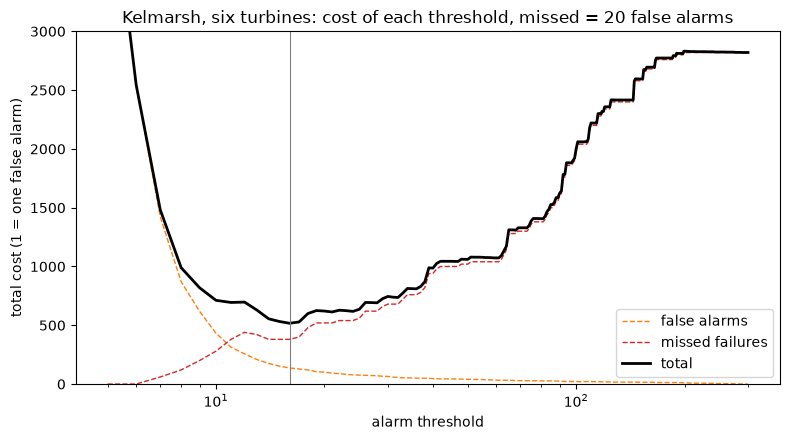

In [18]:
def farm_evaluate(threshold):
    '''evaluate() on every turbine, counts added up, lead times pooled.'''
    total = {'detected': 0, 'missed': 0, 'false_alarms': 0}
    leads = []
    for t in TURBINES:
        r = evaluate(k_test[t], k_failures[t], threshold)
        for key in total:
            total[key] += r[key]
        leads += list(r['lead_times'].dropna().dt.total_seconds() / 3600)
    total['lead_hours'] = np.array(leads)
    return total


k_thresholds = np.arange(5, 301, 1.0)
k_sweep = pd.DataFrame([farm_evaluate(t) for t in k_thresholds], index=k_thresholds)
k_sweep['cost'] = k_sweep['false_alarms'] * COST_FALSE_ALARM + k_sweep['missed'] * COST_MISSED
k_best = k_sweep.index[k_sweep['cost'] == k_sweep['cost'].min()].min()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(k_sweep.index, k_sweep['false_alarms'], color='tab:orange', lw=1, ls='--', label='false alarms')
ax.plot(k_sweep.index, k_sweep['missed'] * COST_MISSED, color='tab:red', lw=1, ls='--', label='missed failures')
ax.plot(k_sweep.index, k_sweep['cost'], color='black', lw=2, label='total')
ax.axvline(k_best, color='grey', lw=0.8)
ax.set_xscale('log')
ax.set_ylim(0, 3000)
ax.set_xlabel('alarm threshold')
ax.set_ylabel('total cost (1 = one false alarm)')
ax.set_title(f'Kelmarsh, six turbines: cost of each threshold, missed = {COST_MISSED} false alarms')
ax.legend()
plt.tight_layout()
fig.savefig(FIGURES / 'kelmarsh_cost_vs_threshold.png', dpi=200)

k_sweep.loc[[8, 10, 12, 15, 20, 30, 60, 100, 150, k_best],
            ['detected', 'missed', 'false_alarms', 'cost']].T

The cheapest threshold is **16**: 122 of 141 outages caught for 137 false alarms. Unlike MetroPT the curve has one clear bottom, because with 141 failures no single one decides it.

At first sight that is a far better result than MetroPT:

In [19]:
r = farm_evaluate(k_best)
train_days = (pd.Timestamp(K_TRAIN[1]) - pd.Timestamp(K_TRAIN[0])) / pd.Timedelta('1D')
k_days = sum((k_test[t].index.max() - k_test[t].index.min()) / pd.Timedelta('1D') - train_days
             for t in TURBINES)   # turbine-days evaluated
lead = pd.Series(r['lead_hours'])

print(f'threshold {k_best:.0f}: {r["detected"]} of {len(all_k)} outages detected, '
      f'{r["false_alarms"]} false alarms')
print(f'one false alarm per turbine every {k_days / r["false_alarms"]:.1f} days\n')
print('warning time of the detections (hours):')
print(pd.cut(lead, [-np.inf, 0, 1, 6, 24, 48],
             labels=['after it started', '0-1', '1-6', '6-24', '24-48']).value_counts(sort=False))

threshold 16: 122 of 141 outages detected, 137 false alarms
one false alarm per turbine every 14.1 days

warning time of the detections (hours):
after it started     6
0-1                 25
1-6                 38
6-24                29
24-48               24
Name: count, dtype: int64


Only 6 of the 122 detections come after the outage has started. The rest are warned about, many by more than a day. If that were true, this would be an excellent detector of protective stops, which notebook 5 said it should not be able to see. So before believing it we check it the same way we checked F4.

### How much of that is chance?

The check we did for F4, but for 141 outages at once. With 2 days of `lead` and
outages clustered in January and February, the windows that count as a detection
cover a fair part of the year. So: **move every alarm on a turbine by the same random
amount of time**, wrapping round at the end of the year, and count detections again.
The alarms keep their number and their spacing but lose any connection to the
outages. 200 random shifts.

In [20]:
def detections(fired, events, upto='end'):
    '''How many events have an alarm in [start - 2 days, end] (or [.., start) if upto='start').'''
    n = 0
    for row in events.itertuples():
        stop = row.end if upto == 'end' else row.start - pd.Timedelta('1s')
        n += bool(((fired >= row.start - pd.Timedelta('2D')) & (fired <= stop)).any())
    return n


def shifted(fired, s, rng):
    span = s.index.max() - s.index.min()
    offset = pd.Timedelta(seconds=rng.uniform(0, span.total_seconds()))
    return pd.DatetimeIndex(s.index.min() + (fired - s.index.min() + offset) % span)


def chance_check(threshold, events, upto='end', runs=200):
    rng = np.random.default_rng(0)
    fired = {t: alarms(k_test[t], threshold) for t in TURBINES}
    real = sum(detections(fired[t], events[t], upto) for t in TURBINES)
    by_chance = [sum(detections(shifted(fired[t], k_test[t], rng), events[t], upto) for t in TURBINES)
                 for _ in range(runs)]
    return {'real': real, 'by chance, mean': np.mean(by_chance),
            'by chance, 95th pct': np.percentile(by_chance, 95)}


pd.DataFrame({t: chance_check(t, k_outages) for t in [k_best, 30, 60]}).T.round(1)

,real,"by chance, mean","by chance, 95th pct"
16.0,122.0,17.9,32.0
30.0,107.0,8.6,24.0
60.0,89.0,5.2,18.0


Shifted at random, the alarms still "detect" about 18 outages, so some of the 122 are luck. But 122 is far above anything chance produces (95th percentile 32). The alarms really are near the outages. The question is why.

### But outages come in clusters

A stop is followed by a restart, and a restart after a stop scores high (notebook 5).
If another outage follows within two days, that restart counts as "warning" of it.
How many outages have an earlier one on the same turbine in the two days before?

In [21]:
isolated = {}
for t in TURBINES:
    o = k_outages[t].sort_values('start').reset_index(drop=True)
    keep = [i for i in range(len(o))
            if not (o['end'].iloc[:i] >= o['start'][i] - pd.Timedelta('2D')).any()]
    isolated[t] = o.iloc[keep]

n_isolated = sum(len(v) for v in isolated.values())
print(f'{len(all_k) - n_isolated} of {len(all_k)} outages follow another within 2 days; '
      f'{n_isolated} are isolated')

91 of 141 outages follow another within 2 days; 50 are isolated


So most "detections" can be the previous outage. The honest test is on the isolated
outages only, and counting only alarms **before the outage starts**: that is a
warning, everything after is the model seeing the stop.

In [22]:
pd.DataFrame({t: chance_check(t, isolated, upto='start') for t in [k_best, 30, 60]}).T.round(1)

,real,"by chance, mean","by chance, 95th pct"
16.0,28.0,6.1,10.0
30.0,13.0,2.9,6.0
60.0,6.0,1.7,4.0


Still more than chance: 28 isolated outages have an alarm in the two days before them, against about 6 by luck. So something does rise before them. Which conditions are the alarms raised in?

In [23]:
cols = ['# Date and time', 'Power (kW)', 'Wind speed (m/s)']
rows = []
for t in TURBINES:
    d = read_kelmarsh('Turbine_Data', t, usecols=cols)
    d.index = pd.to_datetime(d.pop('# Date and time'))
    max_train_wind = d.loc[K_TRAIN[0]:K_TRAIN[1], 'Wind speed (m/s)'].max()
    fired = alarms(k_test[t], k_best)
    for row in isolated[t].itertuples():
        before = fired[(fired >= row.start - pd.Timedelta('2D')) & (fired < row.start)]
        if len(before):
            first = before[0]
            rows.append({'turbine': t, 'outage': row.start.floor('min'), 'cause': row.message,
                         'warning (h)': round((row.start - first).total_seconds() / 3600, 1),
                         'wind (m/s)': round(d.at[first, 'Wind speed (m/s)'], 1),
                         'power (kW)': round(d.at[first, 'Power (kW)']),
                         'wind beyond training': d.at[first, 'Wind speed (m/s)'] > max_train_wind,
                         'already stopped': d.at[first, 'Power (kW)'] < STOPPED_KW})

warned = pd.DataFrame(rows)
print(f'{len(warned)} isolated outages with an alarm before they start: '
      f'{warned["wind beyond training"].sum()} in wind beyond training, '
      f'{warned["already stopped"].sum()} with the turbine already stopped, '
      f'{(~warned["wind beyond training"] & ~warned["already stopped"]).sum()} neither')
warned.sort_values('outage')

28 isolated outages with an alarm before they start: 17 in wind beyond training, 10 with the turbine already stopped, 1 neither


,turbine,outage,cause,warning (h),wind (m/s),power (kW),wind beyond training,already stopped
20,6,2017-01-07 08:53:00,Tower oscillation X level 1,38.7,2.4,-3,False,True
0,1,2017-01-09 11:52:00,Overload generator fan 1,0.4,10.8,-1,False,True
15,5,2017-01-11 12:30:00,Pitch run-away (hub box v.>=4),0.0,14.4,100,True,False
12,4,2017-01-11 13:21:00,Pitch run-away (hub box v.>=4),0.0,14.6,215,True,False
4,2,2017-01-13 10:47:00,Pitch run-away (hub box v.>=4),46.0,18.7,2061,True,False
5,2,2017-01-20 10:37:00,Overload generator fan 3,42.3,2.8,-2,False,True
6,2,2017-01-25 20:23:00,Frequency converter not ready,45.4,6.6,494,False,False
21,6,2017-01-25 20:27:00,Frequency converter not ready,0.5,4.7,-10,False,True
1,1,2017-01-25 20:47:00,Frequency converter not ready,0.5,4.2,-4,False,True
13,4,2017-01-25 20:52:00,Frequency converter not ready,0.4,6.5,-7,False,True


All but one have a plain explanation that is not a fault building up:

- **17 are storms.** The alarm fires in wind stronger than anything in the six spring weeks the model was trained on, mostly at full power, and the turbine then trips on tower oscillation or pitch run-away, usually one to three hours later. 23 February is the same storm on all six turbines. On 23 October four turbines alarm in 16 to 19 m/s wind two days before the remote stop that took the whole farm down.
- **10 were already stopped.** Power is under 10 kW when the alarm fires: the turbine was down for a reason the log does not call a forced outage, and the restart or the standstill scores high.
- **The one left** is turbine 2, 45 hours before a frequency converter fault that hit four turbines within the same half hour on 25 January. That is a grid event; an alarm two days earlier is coincidence.

So the detector does see trouble coming, but the trouble is weather. It is right that a turbine in a storm is likely to trip, but the anemometer already says so, the turbine's own controller already acts on it, and there is nothing for a technician to go and fix. Nothing in the alarms points to a component wearing out, which is what the method is for.

## Kelmarsh: does the threshold move with the cost ratio?

1     59.0
2     32.0
4     24.0
8     17.0
9     16.0
54     9.0
63     8.0
dtype: float64

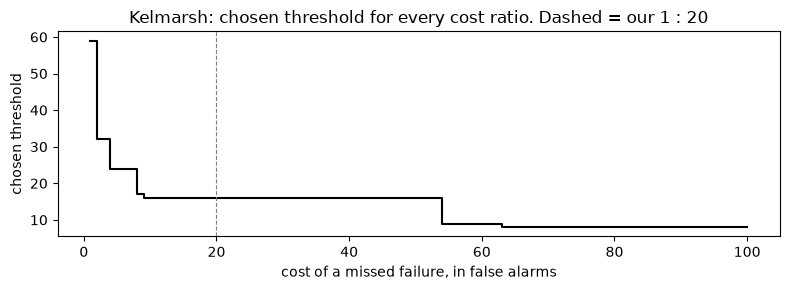

In [24]:
k_chosen = []
for ratio in ratios:
    cost = k_sweep['false_alarms'] + k_sweep['missed'] * ratio
    k_chosen.append(cost.index[cost == cost.min()].min())
k_chosen = pd.Series(k_chosen, index=ratios)

fig, ax = plt.subplots(figsize=(8, 3))
ax.step(ratios, k_chosen, where='post', color='black')
ax.axvline(COST_MISSED, color='grey', lw=0.8, ls='--')
ax.set_xlabel('cost of a missed failure, in false alarms')
ax.set_ylabel('chosen threshold')
ax.set_title('Kelmarsh: chosen threshold for every cost ratio. Dashed = our 1 : 20')
plt.tight_layout()
fig.savefig(FIGURES / 'kelmarsh_threshold_vs_ratio.png', dpi=200)

k_chosen[k_chosen.diff() != 0]

Here the choice is stable. The threshold stays at 16 for any cost ratio from 1 : 9 to 1 : 53, so our 1 : 20 sits in the middle of a wide step. The opposite of MetroPT, where a step lay just below 1 : 20. With 141 failures no single one decides the threshold, and the curve has one bottom.

But the ratio itself is wrong for Kelmarsh. We chose 1 : 20 for a leak that takes a train out of service. The median forced outage here lasts 12 minutes and most reset themselves. Missing one costs far less than 20 site visits. At 1 : 2 the cheapest threshold is already 32, and at 1 : 1 it is 59.

## Kelmarsh: summary

| | Kelmarsh, threshold 16 |
|---|---|
| outages "detected" | 122 of 141 |
| of those, by chance | about 18 |
| false alarms | 137 over six turbines, one per turbine every 14 days |
| isolated outages with an alarm before them | 28 of 50 (about 6 by chance) |
| ... explained by storm or a turbine already stopped | 27 of 28 |
| warnings of a developing fault | none found |

On paper the detector catches most outages with hours of warning. Checked against chance, against clustering and against the conditions at each alarm, it is seeing storms and stops, not wear. This agrees with what notebook 5 found from the scores alone.

## Does the method give the same answer on both datasets?

No, and the difference is in the failures, not the method. The recipe is identical: KDE on a stretch of normal operation, the same alarm rules, the same cost model.

| | MetroPT | Kelmarsh |
|---|---|---|
| failures | 4 air leaks, building over hours | 141 forced outages, median 12 minutes, mostly protective trips |
| caught at the chosen threshold | 3 of 4 (F4 only by chance) | 122 of 141 on paper |
| real early warning of a fault | F3, a day and a half | none |
| what the high scores are | leaks, plus an unreported excursion in May | storms, cold, restarts after stops |
| threshold stable under the cost ratio? | no, a step at 1 : 15 | yes, 1 : 9 to 1 : 53 |

Our hypothesis was that Kelmarsh lead times would be around zero. They are not: on paper they are better than MetroPT's. That turned out to be the more useful lesson. **With many short failures that come in clusters, and a two-day lead window, the detection count says almost nothing on its own.** Raw recall on Kelmarsh is 87 %; what is left after chance, clustering and weather is nothing. On MetroPT, with four failures, one chance check was enough; on Kelmarsh it took three, and each one removed most of what was left.

The second lesson is that the detector flags anything outside what it was trained on. On MetroPT, February and March covered ordinary operation well, so what stood out was mostly the leaks. On Kelmarsh, six spring weeks do not include winter or a storm, so cold and strong wind stand out, and outages happen in exactly those conditions.

## When is this technique the right tool?

Learning normal operation and alarming on deviations is the right tool when:

- **The fault develops before it becomes a failure** and moves the sensors while it does. MetroPT F3 is the example: a day and a half of warning. Even there the warning rests on a single alarm just under the noise, so it is fragile.
- **The fault shows in the sensors we model.** F4 left no trace in the seven compressor sensors, and no threshold finds it except by chance.
- **The training period covers every normal condition the machine will meet.** Kelmarsh shows what happens otherwise: a model that has never seen a storm flags every storm, and since storms cause trips, it looks like a detector until you check what it is reacting to.
- **There is plenty of normal data and few failures.** That is exactly why we could not train a classifier on MetroPT.
- **A false alarm is cheap compared with a miss.** Even a sensible threshold produces a false alarm every one to three weeks on both datasets.

It is the wrong tool when the failure is a sudden event: a protective trip, a grid fault, a broken part with no wear before it. Kelmarsh is that case. The detector adds nothing the turbine's own controller and anemometer do not already know, and it confirms stops after the fact. It is also the wrong tool when nobody can put a rough price on a false alarm against a miss, because on MetroPT the choice of threshold depends on it.

Whatever the dataset, a detection count has to be checked against chance before it is reported. A random alarm lands near a failure surprisingly often when the failures are many, short and clustered.